# Life-stage polities
Each individual gets a polity for each stage of life: early (birth → first work), active (first work → last work), late (last work → death) when the work period comes from dated works; otherwise early (birth → 30), active (30 → 60) and late (60 → death). The stage's Wikidata fields are tried in priority order; a location is matched to the Cliopatria polities that held it during the stage, by Wikipedia link first, coordinates otherwise, and only the smallest polity of the Cliopatria hierarchy is kept. Run on a sample, before any ingestion.

In [1]:
import json
import sys
from pathlib import Path
from urllib.parse import unquote

import duckdb
import polars as pl
from shapely import STRtree, make_valid, points
from shapely.geometry import shape

sys.path.insert(0, '../notebooks_analysis')
from style import show_table

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
LIFE_LOCATIONS = Path('../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations')
CLIOPATRIA = Path('../../data/cliopatria_data/cliopatria_V2/cliopatria_polities_only_v3.geojson')
SAMPLE_SIZE = 10_000
SEED = 42
EXAMPLES = ['Q36620', 'Q8963']  # Tycho Brahe and Johannes Kepler, added to the sample

PROPERTIES = {'P937': 'work_location', 'P551': 'residence', 'P108': 'employer', 'P69': 'educated_at', 'P39': 'position_held'}
SOURCES = {
    'place_of_birth': 'birthplace', 'educated_at': 'school', 'residence': 'residence', 'country_of_citizenship': 'citizenship',
    'work_location': 'work location', 'employer': 'employer', 'position_held': 'position held', 'place_of_death': 'deathplace',
}
STAGES = ['early', 'active', 'late']
ACTIVE_AGE, LATE_AGE = 30, 60  # stage limits of the individuals without a dated work period
MIN_STAGE = 5  # years: a shorter early or late stage is merged into the active stage
RULES = {
    'early': [('place_of_birth', 'certain'), ('educated_at', 'certain'), ('residence', 'unsure'), ('country_of_citizenship', 'unsure'), ('work_location', 'unsure'), ('employer', 'unsure'), ('position_held', 'unsure'), ('place_of_death', 'unsure')],
    'active': [('work_location', 'certain'), ('employer', 'certain'), ('position_held', 'certain'), ('residence', 'certain'), ('educated_at', 'unsure'), ('country_of_citizenship', 'unsure'), ('place_of_birth', 'unsure'), ('place_of_death', 'unsure')],
    'late': [('place_of_death', 'certain'), ('residence', 'unsure'), ('work_location', 'unsure'), ('position_held', 'unsure'), ('employer', 'unsure'), ('country_of_citizenship', 'unsure'), ('educated_at', 'unsure'), ('place_of_birth', 'unsure')],
}
METHODS = ['URL', 'coordinates']  # the Wikipedia URL is always tried first

pl.Config.set_tbl_rows(50)
pl.Config.set_fmt_str_lengths(80)
pl.Config.set_tbl_width_chars(300)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

## Data
Individuals with a birth and a death year (seeded sample, plus Tycho Brahe and Kepler), their work period when it comes from dated works over more than one year, and their eight location fields from the database: birthplace, deathplace, citizenship, and the five life-location fields of step 08 (work location, residence, employer, educated at, position held; deprecated statements dropped).

In [2]:
connection = duckdb.connect(DB_PATH, read_only=True)
sample = connection.sql(f'''
    WITH dated AS (
        SELECT entity.qid AS qid, entity.label_en AS name, birth_date.year AS birth, death_date.year AS death,
               coalesce(first_work_date.source = 'dated works' AND first_work_date.year < last_work_date.year, false) AS dated_works,
               CASE WHEN dated_works THEN first_work_date.year END AS first_work,
               CASE WHEN dated_works THEN last_work_date.year END AS last_work
        FROM individual_enriched
        WHERE birth_date.year IS NOT NULL AND death_date.year IS NOT NULL
    ),
    picked AS (
        (SELECT * FROM dated ORDER BY hash(qid || '{SEED}') LIMIT {SAMPLE_SIZE})
        UNION
        (SELECT * FROM dated WHERE qid IN {tuple(EXAMPLES)})
    )
    SELECT picked.*,
           [individual.place_of_birth.entity.qid] AS place_of_birth,
           [individual.place_of_death.entity.qid] AS place_of_death,
           list_transform(individual.country_of_citizenship, country -> country.entity.qid) AS country_of_citizenship,
           list_transform(individual.work_location, place -> place.entity.qid) AS work_location,
           list_transform(individual.residence, place -> place.entity.qid) AS residence,
           list_transform(individual.employer, institution -> institution.entity.qid) AS employer,
           list_transform(individual.educated_at, institution -> institution.entity.qid) AS educated_at,
           individual.position_held AS position_held
    FROM picked JOIN individual ON individual.entity.qid = picked.qid
''').pl().with_columns(pl.col('place_of_birth', 'place_of_death').list.drop_nulls())

people = sample
assert people['qid'].is_unique and people['qid'].is_in(EXAMPLES).sum() == len(EXAMPLES)
life_locations = sum(people[field].list.len().sum() for field in PROPERTIES.values())
print(f'{people.height:,} individuals, {life_locations:,} life-location values')


10,002 individuals, 6,780 life-location values


### Stage limits
With a dated work period, the stages are cut at the first and the last work; otherwise at ages 30 and 60. A stage is dropped when it ends before it starts (inconsistent dates, or a death before the stage); an early or late stage shorter than 5 years is merged into the active stage, and an active stage shorter than 5 years with no late stage into the early one.

In [3]:
def stage_limits(person):
    birth, death = person['birth'], person['death']
    if person['dated_works']:
        first, last = person['first_work'], person['last_work']
    else:
        first, last = birth + ACTIVE_AGE, birth + LATE_AGE
    limits = {'early': [birth, min(first, death)], 'active': [first, min(last, death)], 'late': [last, death]}
    limits = {stage: bounds for stage, bounds in limits.items() if bounds[0] <= bounds[1]}
    early, active, late = (limits.get(stage) for stage in STAGES)
    if late and active and late[1] - late[0] < MIN_STAGE:
        active[1] = limits.pop('late')[1]
    if early and active and early[1] - early[0] < MIN_STAGE:
        active[0] = limits.pop('early')[0]
    if active and early and 'late' not in limits and active[1] - active[0] < MIN_STAGE:
        early[1] = limits.pop('active')[1]
    return limits


windows = pl.DataFrame(
    [{'qid': person['qid'], 'stage': stage, 'start': start, 'end': end} for person in people.iter_rows(named=True) for stage, (start, end) in stage_limits(person).items()],
    schema={'qid': pl.String, 'stage': pl.String, 'start': pl.Int64, 'end': pl.Int64},
)
inconsistent = people.filter((pl.col('death') < pl.col('birth')) | (pl.col('dated_works') & ((pl.col('first_work') < pl.col('birth')) | (pl.col('last_work') > pl.col('death')))))
print(f"{people['dated_works'].sum():,} individuals with a dated work period, {(~people['dated_works']).sum():,} cut at ages {ACTIVE_AGE} and {LATE_AGE}")
print(f'{inconsistent.height:,} individuals with inconsistent dates (death before birth, or works outside the life): their stages outside the life are dropped')
windows.group_by('stage').len().sort(pl.col('stage').cast(pl.Enum(STAGES)))

291 individuals with a dated work period, 9,711 cut at ages 30 and 60
0 individuals with inconsistent dates (death before birth, or works outside the life): their stages outside the life are dropped


stage,len
"""early""",9999
"""active""",9486
"""late""",6489


### Spots
Where each location is tested: a place at itself, an employer or a school at its location in the Institution table (P131, else P159, else P276), a position held at its jurisdiction (P1001, from the extraction until positions are in the database). Each spot has its English Wikipedia article and its coordinates from the Place table, else the extraction for jurisdictions.

In [4]:
def article(url):
    return unquote(url.rsplit('/wiki/', 1)[-1]).replace('_', ' ')


targets = json.loads((LIFE_LOCATIONS / 'targets.json').read_text())
place_rows = connection.sql('SELECT entity.qid, entity.label_en, sitelink.url, coordinates.longitude, coordinates.latitude FROM place').fetchall()
label = {qid: target['label_en'] for qid, target in targets.items() if target['label_en']}  # the Place table has double-encoded labels
link = {qid: article(url) for qid, _, url, _, _ in place_rows if url}
point = {qid: (longitude, latitude) for qid, _, _, longitude, latitude in place_rows if latitude is not None}
for qid, name, _, _, _ in place_rows:
    if name:
        label.setdefault(qid, name)
for target in targets.values():
    for spot, coordinates in target['jurisdiction'].items():
        if coordinates:
            point.setdefault(spot, (coordinates['longitude'], coordinates['latitude']))
institution_location = dict(connection.sql('SELECT entity.qid, location.entity.qid FROM institution WHERE location IS NOT NULL').fetchall())


def spots(source, qid):
    if source in ('employer', 'educated_at'):
        return [institution_location[qid]] if qid in institution_location else []
    if source == 'position_held':
        return list(targets.get(qid, {}).get('jurisdiction', {}))
    return [qid]

### Cliopatria polities and their hierarchy
Read from the Cliopatria file itself, since the database's `meta_polities` and `child_polities` are empty. A polity's parents are its `MemberOf` and every polity listing it in its `Components`; meta polities keep their parenthesised names, e.g. `(British Empire)`.

In [5]:
features = json.loads(CLIOPATRIA.read_text())['features']
territories = pl.DataFrame([{key: feature['properties'][key] for key in ['Name', 'FromYear', 'ToYear', 'Wikipedia', 'Type']} for feature in features])
tree = STRtree(make_valid([shape(feature['geometry']) for feature in features]))
name_of, start_of, end_of = territories['Name'].to_list(), territories['FromYear'].to_list(), territories['ToYear'].to_list()
by_link = {}
for index, title in enumerate(territories['Wikipedia']):
    if title:
        by_link.setdefault(title.replace('_', ' '), []).append(index)

parents = {}
for feature in features:
    properties = feature['properties']
    for parent in filter(None, properties['MemberOf'].split(';')):
        parents.setdefault(properties['Name'], set()).add(parent)
    for child in filter(None, properties['Components'].split(';')):
        parents.setdefault(child, set()).add(properties['Name'])


def ancestors(name):
    found, todo = set(), [name]
    while todo:
        for parent in parents.get(todo.pop(), ()):
            if parent not in found:
                found.add(parent)
                todo.append(parent)
    return found


print(f'{territories.height:,} territories of {territories["Name"].n_unique():,} polities; {len(parents):,} polities have a parent')

13,755 territories of 1,633 polities; 336 polities have a parent


In [6]:
sample_spots = sorted({spot for source in SOURCES for qids in people[source] for qid in qids for spot in spots(source, qid) if spot in point})
spot_index, territory_index = tree.query(points([point[spot] for spot in sample_spots]), predicate='within')
containing = {}
for spot, territory in zip(spot_index, territory_index):
    containing.setdefault(sample_spots[spot], []).append(int(territory))

## Assignment
For a stage, the fields are tried in order; each location is tested by link, then by coordinates. A territory matches when it held the spot during the stage; a polity that is an ancestor of another matched polity is dropped, so only the smallest remain. The first field with a match ends the search. Every location of that field gives its polity held longest during the stage, so a stage keeps a list of polities, longest first.

In [7]:
def smallest_polities(indices, start, end):
    years = {}
    for index in indices:
        low, high = max(start_of[index], start), min(end_of[index], end)
        if low <= high:
            years.setdefault(name_of[index], set()).update(range(low, high + 1))
    above = {parent for name in years for parent in ancestors(name)}
    return {name: len(covered) for name, covered in years.items() if name not in above}


def locate(source, qid, start, end):
    for method in METHODS:
        for spot in spots(source, qid):
            indices = by_link.get(link.get(spot), []) if method == 'URL' else containing.get(spot, [])
            found = smallest_polities(indices, start, end)
            if found:
                return method, spot, found
    return None


def assign(person, stage, start, end):
    for source, certainty in RULES[stage]:
        located = [hit for qid in person[source] if (hit := locate(source, qid, start, end))]
        if located:
            polities = {}
            for _, _, found in located:
                polity = max(found, key=found.get)
                polities[polity] = max(found[polity], polities.get(polity, 0))
            ranked = sorted(polities, key=polities.get, reverse=True)
            return {
                'polities': [polity.strip('()') for polity in ranked], 'years': [polities[polity] for polity in ranked],
                'rule': SOURCES[source], 'certainty': certainty,
                'method': ' + '.join(sorted({method for method, _, _ in located})),
                'location': '; '.join(dict.fromkeys(label.get(spot, spot) for _, spot, _ in located)),
            }
    return {'polities': [], 'years': [], 'rule': None, 'certainty': 'none', 'method': None, 'location': None}


person_of = {person['qid']: person for person in people.iter_rows(named=True)}
assignments = pl.DataFrame(
    [{**window, **assign(person_of[window['qid']], window['stage'], window['start'], window['end'])} for window in windows.iter_rows(named=True)],
    schema_overrides={'polities': pl.List(pl.String), 'years': pl.List(pl.Int64)},
).with_columns(polity=pl.col('polities').list.join('; '))
assert assignments.height == windows.height

## Results
### Certainty per stage (% of the individuals with that stage)

In [8]:
(
    assignments.group_by('stage', 'certainty').len()
    .with_columns(individuals=pl.col('len').sum().over('stage'), share=(100 * pl.col('len') / pl.col('len').sum().over('stage')).round(1))
    .pivot(on='certainty', index=['stage', 'individuals'], values='share')
    .select('stage', 'individuals', 'certain', 'unsure', 'none')
    .sort(pl.col('stage').cast(pl.Enum(STAGES)))
)

stage,individuals,certain,unsure,none
"""early""",9999,50.3,21.4,28.2
"""active""",9486,21.2,50.9,27.9
"""late""",6489,37.7,35.4,26.9


### One individual per century
For each century of birth, the named individual of the sample matched at the most stages, then with the most certain stages. Each cell: polity — rule: location value (certainty, method: URL or coordinates).

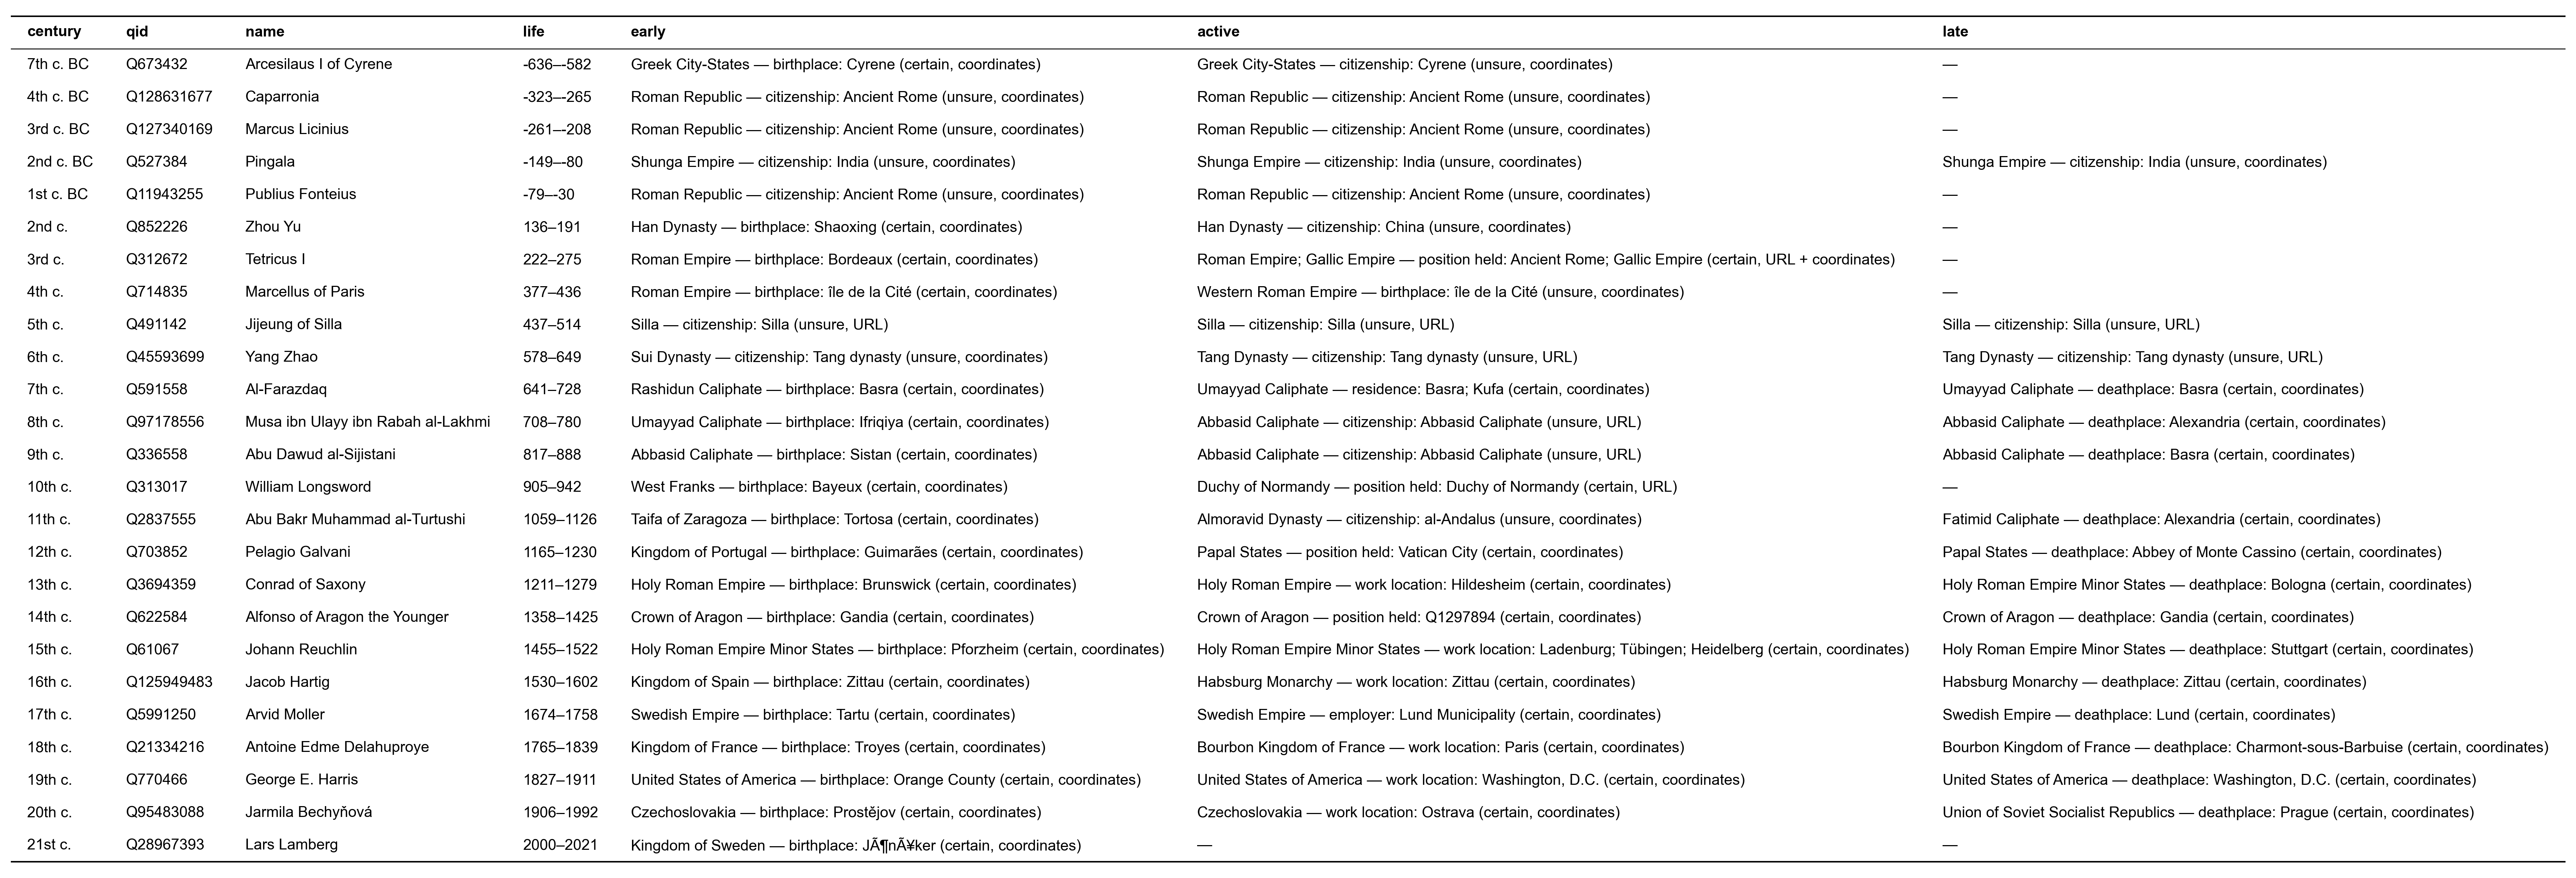

In [9]:
def century(year):
    number = abs(year) // 100 + 1 if year >= 0 else (abs(year) - 1) // 100 + 1
    suffix = 'th' if 10 <= number % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(number % 10, 'th')
    return f"{number}{suffix} c.{' BC' if year < 0 else ''}"


cells = assignments.with_columns(
    cell=pl.when(pl.col('rule').is_not_null()).then(pl.format('{} — {}: {} ({}, {})', 'polity', 'rule', 'location', 'certainty', 'method')).otherwise(pl.lit('—'))
).pivot(on='stage', index='qid', values='cell')
matched = assignments.group_by('qid').agg((pl.col('certainty') != 'none').sum().alias('matched'), (pl.col('certainty') == 'certain').sum().alias('certain'))
per_century = (
    sample.select('qid', 'name', 'birth', 'death').drop_nulls('name')
    .join(cells, on='qid').join(matched, on='qid')
    .with_columns(pl.col(STAGES).fill_null('—'))
    .with_columns(order=pl.when(pl.col('birth') >= 0).then(pl.col('birth') // 100).otherwise(-((-pl.col('birth') - 1) // 100) - 1))
    .sort('order', 'matched', 'certain', pl.col('qid').hash(SEED), descending=[False, True, True, False])
    .unique('order', keep='first', maintain_order=True)
    .select(
        pl.col('birth').map_elements(century, return_dtype=pl.String).alias('century'),
        'qid', 'name', pl.format('{}–{}', 'birth', 'death').alias('life'), 'early', 'active', 'late',
    )
)
show_table(per_century, font_size=10)

### Tycho Brahe and Johannes Kepler

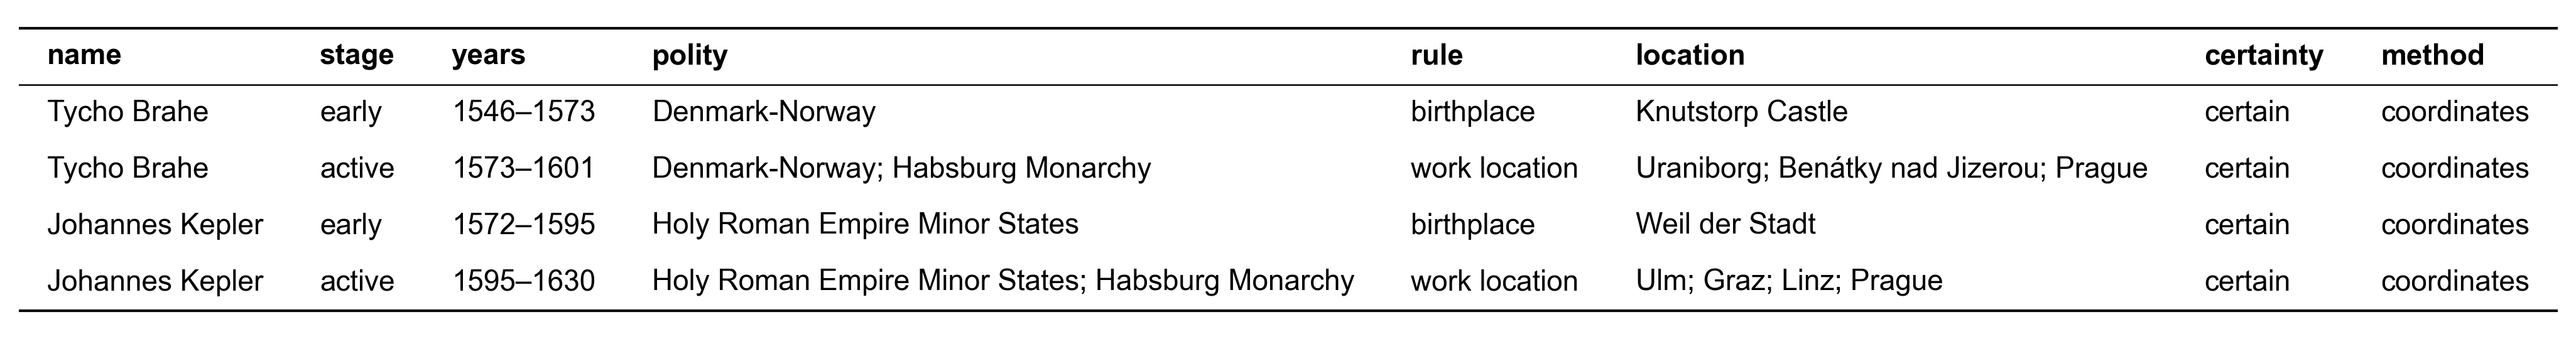

In [10]:
show_table(
    assignments.filter(pl.col('qid').is_in(EXAMPLES))
    .join(sample, on='qid')
    .sort('birth', pl.col('stage').cast(pl.Enum(STAGES)))
    .select('name', 'stage', pl.format('{}–{}', 'start', 'end').alias('years'), 'polity', 'rule', 'location', 'certainty', 'method')
)

### How each stage is found
Share of the individuals with that stage (%) found by each field and method; a stage whose locations matched by both methods counts under URL + coordinates. The fields are listed in the order of the early-stage rule.

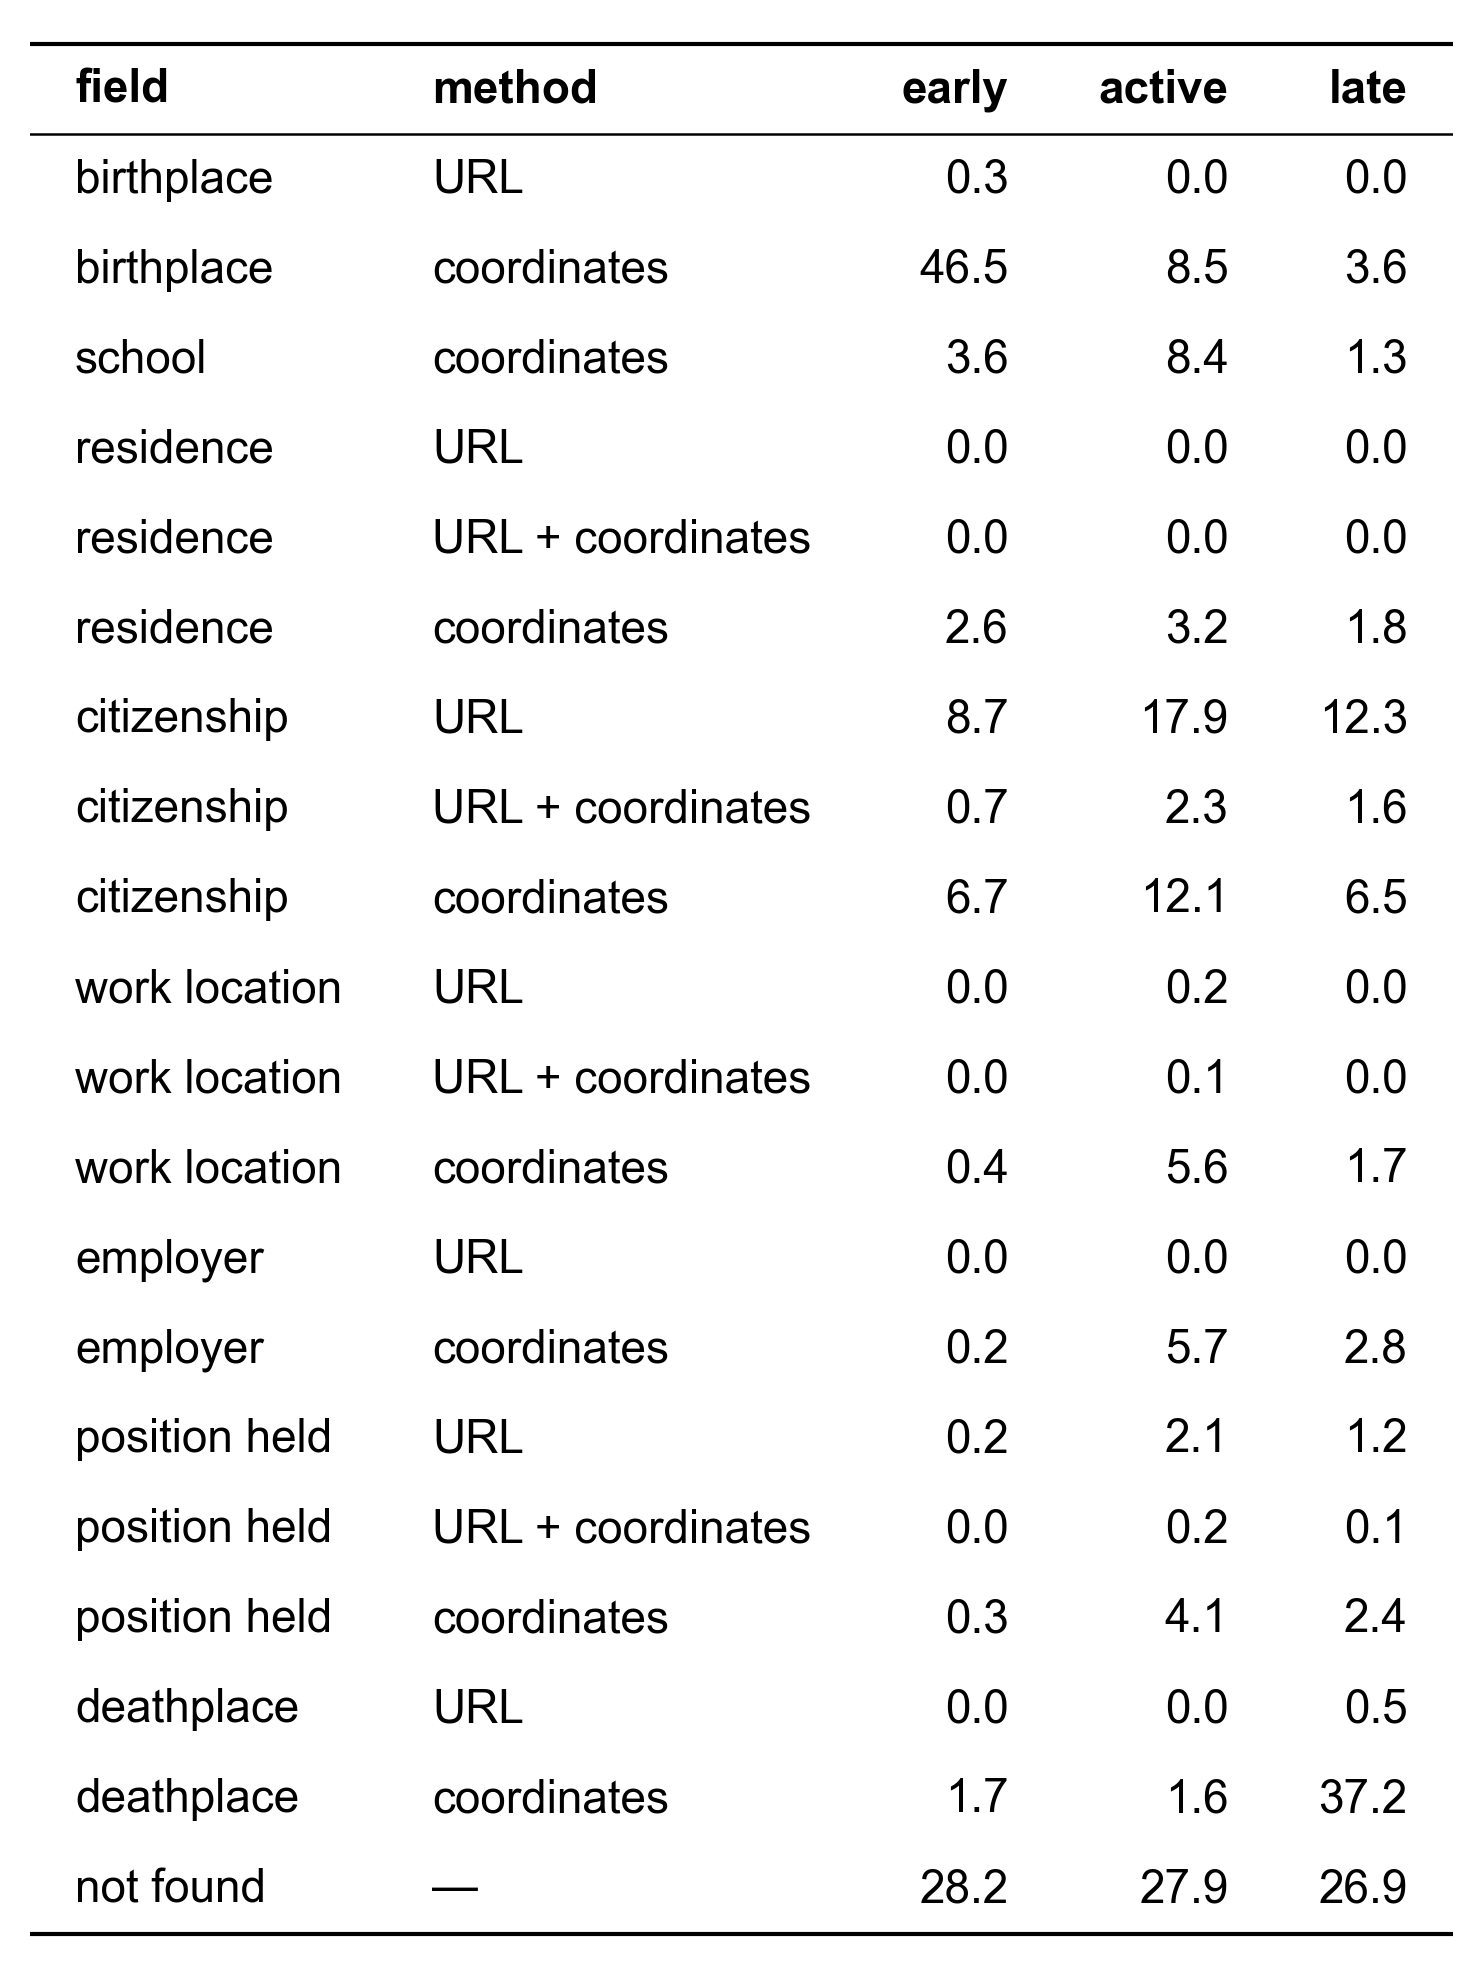

In [11]:
found_by = (
    assignments.with_columns(
        field=pl.col('rule').fill_null('not found'),
        method=pl.col('method').fill_null('—'),
        individuals=pl.len().over('stage'),
    )
    .group_by('stage', 'field', 'method').agg(share=100 * pl.len() / pl.col('individuals').first())
    .pivot(on='stage', index=['field', 'method'], values='share')
    .with_columns(pl.col(STAGES).fill_null(0.0))
    .sort(
        pl.col('field').replace_strict({name: rank for rank, name in enumerate([*SOURCES.values(), 'not found'])}),
        pl.col('method').replace_strict({'URL': 0, 'URL + coordinates': 1, 'coordinates': 2, '—': 3}),
    )
    .select('field', 'method', *STAGES)
)
show_table(found_by, decimals=1)